<a href="https://colab.research.google.com/github/24jangdecp-debug/Machine-Learning-Lab-Code-5th-Sem/blob/main/ChaitanyaJ_lab5_ml_C4_55.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# LAB-5: KNN Classification and Regression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.metrics import (
 accuracy_score, confusion_matrix, classification_report,
 mean_squared_error, r2_score
)

In [3]:
# PART A: KNN CLASSIFICATION
# -----------------------------
iris = load_iris()
X = iris.data
y = iris.target
X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.20, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
k = 5
knn_clf = KNeighborsClassifier(n_neighbors=k)
knn_clf.fit(X_train_scaled, y_train)
y_pred = knn_clf.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)
print("KNN CLASSIFICATION")
print("K =", k)
print("Accuracy =", accuracy)
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

KNN CLASSIFICATION
K = 5
Accuracy = 0.9333333333333333

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30




KNN REGRESSION
K = 5
Mean Squared Error = 177.94239757068186
R2 Score = 0.9666041842114237


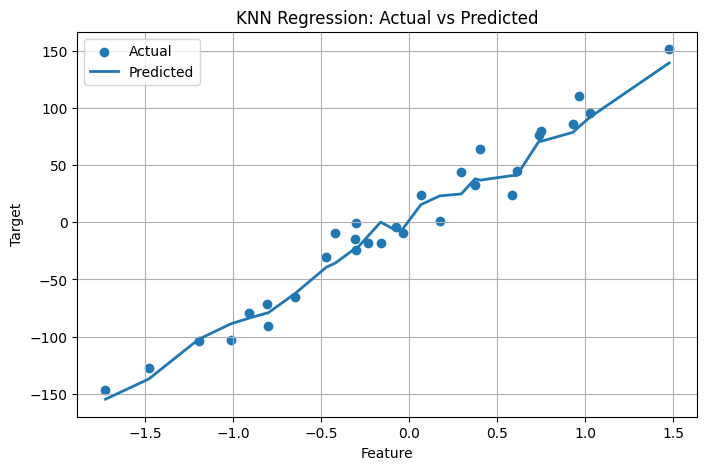

In [4]:
# PART B: KNN REGRESSION

X_reg, y_reg = make_regression(
 n_samples=150,
 n_features=1,
 noise=15,
 random_state=42
)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
 X_reg, y_reg, test_size=0.20, random_state=42
)
reg_scaler = StandardScaler()
Xr_train_scaled = reg_scaler.fit_transform(Xr_train)
Xr_test_scaled = reg_scaler.transform(Xr_test)
k_reg = 5
knn_reg = KNeighborsRegressor(n_neighbors=k_reg)
knn_reg.fit(Xr_train_scaled, yr_train)
yr_pred = knn_reg.predict(Xr_test_scaled)
mse = mean_squared_error(yr_test, yr_pred)
r2 = r2_score(yr_test, yr_pred)
print("\nKNN REGRESSION")
print("K =", k_reg)
print("Mean Squared Error =", mse)
print("R2 Score =", r2)
# Regression output plot
order = np.argsort(Xr_test[:, 0])
plt.figure(figsize=(8, 5))
plt.scatter(Xr_test[:, 0], yr_test, label="Actual")
plt.plot(
 Xr_test[order, 0],
 yr_pred[order],
 label="Predicted",
 linewidth=2
)
plt.xlabel("Feature")
plt.ylabel("Target")
plt.title("KNN Regression: Actual vs Predicted")
plt.legend()
plt.grid(True)
plt.show()